# SPD Brain Connectomes — MLSP/COBRE Results

**Goal.** Compare four 2-D representations of the same 86 brain-connectome subjects. PCA is Euclidean; tangent PCA first maps SPD matrices to a linear tangent space; the autoencoder and MIAF learn nonlinear embeddings.

In [1]:
# Imports and reproducibility
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")
np.random.seed(42)
torch.manual_seed(42)
plt.rcParams["figure.dpi"] = 130

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
TRAIN = ROOT / "train"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
print(ROOT)


C:\Users\Globaltech\Reduction-des-matrices-SPD


In [2]:
# Data: 86 subjects, 378 FNC values, labels
fnc = pd.read_csv(TRAIN / "train_FNC.csv")
labels_df = pd.read_csv(TRAIN / "train_labels.csv")
assert np.array_equal(fnc["Id"].to_numpy(), labels_df["Id"].to_numpy())

ids = fnc["Id"].to_numpy()
X = fnc.drop(columns=["Id"]).to_numpy(dtype=np.float64)
y = labels_df["Class"].to_numpy(dtype=np.int64)
rows, cols = np.triu_indices(28, k=1)

print(f"subjects={len(y)}, features={X.shape[1]}, classes={dict(zip(*np.unique(y, return_counts=True)))}")


subjects=86, features=378, classes={np.int64(0): np.int64(46), np.int64(1): np.int64(40)}


In [3]:
# SPD construction and tangent coordinates
def vectors_to_symmetric(vectors):
    matrices = np.zeros((len(vectors), 28, 28), dtype=np.float64)
    matrices[:, rows, cols] = vectors
    matrices[:, cols, rows] = vectors
    return matrices


def matrix_exp_symmetric(matrix):
    eigenvalues, eigenvectors = np.linalg.eigh(matrix)
    return (eigenvectors * np.exp(eigenvalues)) @ eigenvectors.T


def matrix_log_spd(matrix):
    eigenvalues, eigenvectors = np.linalg.eigh(matrix)
    if np.any(eigenvalues <= 0):
        raise ValueError("Matrix is not SPD.")
    return (eigenvectors * np.log(eigenvalues)) @ eigenvectors.T


symmetric = vectors_to_symmetric(X)
spd = np.stack([matrix_exp_symmetric(matrix) for matrix in symmetric])
spd_eigenvalues = np.linalg.eigvalsh(spd)
log_spd = np.stack([matrix_log_spd(matrix) for matrix in spd])
tangent = log_spd[:, rows, cols].astype(np.float32)

assert np.all(spd_eigenvalues > 0)
print(f"SPD shape={spd.shape}, tangent shape={tangent.shape}")
print(f"minimum eigenvalue={spd_eigenvalues.min():.6f}")


SPD shape=(86, 28, 28), tangent shape=(86, 378)
minimum eigenvalue=0.368715


### Why the exponential gives SPD matrices

For each symmetric connectivity matrix, use the eigendecomposition
$$
A = Q \Lambda Q^{\mathsf T},
$$
where \(Q\) is orthogonal and
\(\Lambda=\operatorname{diag}(\lambda_1,\ldots,\lambda_{28})\).
The matrix exponential is
$$
S=\exp(A)
  =Q\,\operatorname{diag}\!\left(e^{\lambda_1},\ldots,e^{\lambda_{28}}\right)
   Q^{\mathsf T}.
$$
Because \(e^{\lambda_i}>0\) for every \(i\), all eigenvalues of \(S\) are
strictly positive. Therefore \(S=S^{\mathsf T}\succ0\), so \(S\) is SPD.
The inverse spectral map is
$$
\log(S)=Q\,\operatorname{diag}\!\left(\log \mu_1,\ldots,\log \mu_{28}\right)
Q^{\mathsf T},
$$
where \(\mu_i>0\) are the eigenvalues of \(S\). These log-coordinates are
used by tangent PCA.


In [4]:
# PCA and tangent PCA
def scale_pca(features):
    scaled = StandardScaler().fit_transform(features)
    return PCA(n_components=2, random_state=42).fit_transform(scaled)


Z_pca = scale_pca(spd.reshape(len(spd), -1))
Z_tangent_pca = scale_pca(tangent)


### Géométrie locale avec plusieurs repères

Un seul espace tangent peut être insuffisant lorsque les connectomes sont
répartis sur plusieurs régions courbées. Le nombre de repères n'est pas imposé :
un seul repère est conservé si les données ne montrent pas de séparation
riemannienne fiable. Sinon, plusieurs centres SPD sont calculés et chaque
sujet est affecté à son repère le plus proche. Les coordonnées locales sont
ensuite transportées vers un repère commun.

In [5]:
# Multi-reference local geometry
import sys

sys.path.insert(0, str(ROOT))
from spd_reduction.local_geometry import (
    affine_invariant_distance,
    pairwise_affine_invariant_distances,
    aligned_local_tangent_coordinates,
    riemannian_mean,
    summarize_local_geometry,
)

local_summary, local_centers, local_assignments, local_tangent = (
    summarize_local_geometry(spd)
)
local_tangent = aligned_local_tangent_coordinates(
    spd, local_centers, local_assignments, riemannian_mean(spd)
)
local_distance = np.asarray([
    affine_invariant_distance(matrix, local_centers[group])
    for matrix, group in zip(spd, local_assignments)
])
local_geometry_table = pd.DataFrame({
    "Id": ids,
    "Class": y,
    "local_reference": local_assignments,
    "riemannian_distance_to_reference": local_distance,
})
local_geometry_table.to_csv(ROOT / "local_geometry_subject_assignments.csv", index=False)
local_center_distances = pd.DataFrame(
    pairwise_affine_invariant_distances(local_centers),
    index=[f"Repère {i}" for i in range(local_summary["n_centers"])],
    columns=[f"Repère {i}" for i in range(local_summary["n_centers"])],
)
local_center_distances.to_csv(ROOT / "local_geometry_center_distances.csv")
print("number of local references:", local_summary["n_centers"])
print("silhouette scores:", local_summary["silhouette_scores"])
print(local_geometry_table.groupby("local_reference").size())
print("mean distance to local reference:", local_distance.mean())
print("distances between local references:")
display(local_center_distances)


KeyboardInterrupt: 

In [ ]:
# Accuracy: global versus multi-reference tangent PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

local_embeddings = {
    "Tangent PCA globale": Z_tangent_pca,
    "Repères adaptatifs": scale_pca(local_tangent),
}
local_classifiers = {
    "kNN": KNeighborsClassifier(n_neighbors=5),
    "Logistic": LogisticRegression(max_iter=2000, random_state=42),
    "SVM": SVC(kernel="rbf", random_state=42),
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=42),
}
local_accuracy_rows = []
for reducer, embedding in local_embeddings.items():
    for classifier_name, classifier_template in local_classifiers.items():
        scores = []
        for seed in range(10):
            train_idx, test_idx = train_test_split(
                np.arange(len(y)), test_size=0.2, random_state=seed, stratify=y
            )
            classifier_template.fit(embedding[train_idx], y[train_idx])
            scores.append(
                accuracy_score(y[test_idx], classifier_template.predict(embedding[test_idx]))
            )
        local_accuracy_rows.append({
            "Reducer": reducer,
            "Classifier": classifier_name,
            "Mean_Accuracy": np.mean(scores),
            "Std_Accuracy": np.std(scores),
        })
local_accuracy = pd.DataFrame(local_accuracy_rows)
local_accuracy.to_csv(ROOT / "local_geometry_accuracy.csv", index=False)
local_accuracy.round(4)


,Reducer,Classifier,Mean_Accuracy,Std_Accuracy
0,Tangent PCA globale,kNN,0.6889,0.0831
1,Tangent PCA globale,Logistic,0.6778,0.1018
2,Tangent PCA globale,SVM,0.6222,0.0853
3,Tangent PCA globale,Random forest,0.5389,0.0788
4,Repères adaptatifs,kNN,0.6056,0.0764
5,Repères adaptatifs,Logistic,0.6333,0.0444
6,Repères adaptatifs,SVM,0.6444,0.0711
7,Repères adaptatifs,Random forest,0.5722,0.0558


### PCA versus tangent PCA

**Euclidean PCA.** Flatten each SPD matrix \(S_i\) into a vector
\(\operatorname{vec}(S_i)\), standardize the features, and find two
directions of maximum variance:
$$
Z_{\mathrm{PCA}}
  =\operatorname{PCA}_2\!\left(
    \operatorname{StandardScaler}\!\left[
      \operatorname{vec}(S_1),\ldots,\operatorname{vec}(S_{86})
    \right]\right).
$$

**Tangent PCA.** First map each SPD matrix to the logarithm, retain its
strict upper triangle \(u_i=\operatorname{upper}(\log S_i)\), and then
apply the same two-component PCA:
$$
Z_{\mathrm{TPCA}}
  =\operatorname{PCA}_2\!\left(
    \operatorname{StandardScaler}\!\left[
      u_1,\ldots,u_{86}
    \right]\right).
$$
The logarithm converts the curved SPD space into a locally Euclidean
tangent representation before dimensionality reduction.

In [ ]:
# Autoencoder
class Autoencoder(nn.Module):
    def __init__(self, input_dim, hidden=(189, 47, 11), latent_dim=2):
        super().__init__()
        encoder = []
        previous = input_dim
        for width in hidden:
            encoder += [nn.Linear(previous, width), nn.ReLU()]
            previous = width
        encoder.append(nn.Linear(previous, latent_dim))
        decoder = []
        previous = latent_dim
        for width in reversed(hidden):
            decoder += [nn.Linear(previous, width), nn.ReLU()]
            previous = width
        decoder.append(nn.Linear(previous, input_dim))
        self.encoder = nn.Sequential(*encoder)
        self.decoder = nn.Sequential(*decoder)

    def forward(self, features):
        latent = self.encoder(features)
        return self.decoder(latent), latent


def train_autoencoder(features, epochs=100):
    model = Autoencoder(features.shape[1])
    data = torch.from_numpy(features.astype(np.float32))
    loader = DataLoader(TensorDataset(data), batch_size=32, shuffle=True)
    optimizer = optim.AdamW(model.parameters(), lr=1e-3)
    criterion = nn.MSELoss()
    losses = []
    for _ in range(epochs):
        total = 0.0
        for (batch,) in loader:
            optimizer.zero_grad()
            reconstruction, _ = model(batch)
            loss = criterion(reconstruction, batch)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(batch)
        losses.append(total / len(features))
    return model, losses


ae_model, ae_losses = train_autoencoder(tangent)
with torch.no_grad():
    Z_autoencoder = ae_model.encoder(torch.from_numpy(tangent)).numpy()


In [ ]:
# MIAF
def group_features(features, bins=20, threshold=0.5):
    histograms = []
    for feature in features.T:
        counts, _ = np.histogram(feature, bins=bins)
        counts = counts.astype(float) + 1e-12
        histograms.append(counts / counts.sum())
    histograms = np.asarray(histograms)
    distances = np.zeros((len(histograms), len(histograms)))
    for i in range(len(histograms)):
        for j in range(i + 1, len(histograms)):
            p, q = histograms[i], histograms[j]
            distances[i, j] = distances[j, i] = 0.5 * (
                np.sum(p * np.log(p / q)) + np.sum(q * np.log(q / p))
            )
    from scipy.cluster.hierarchy import fcluster, linkage
    from scipy.spatial.distance import squareform
    cluster_ids = fcluster(
        linkage(squareform(distances, checks=False), method="average"),
        threshold,
        criterion="distance",
    )
    groups = {}
    for index, cluster_id in enumerate(cluster_ids):
        groups.setdefault(int(cluster_id), []).append(index)
    return [np.asarray(group, dtype=np.int64) for group in groups.values()]


class MIAF(nn.Module):
    def __init__(self, groups, latent_dim=2):
        super().__init__()
        self.groups = groups
        self.encoders = nn.ModuleList([
            nn.Sequential(nn.Linear(len(group), 16), nn.ReLU(), nn.Linear(16, 16), nn.ReLU())
            for group in groups
        ])
        encoded_dim = 16 * len(groups)
        self.selector = nn.Linear(encoded_dim, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, sum(len(group) for group in groups)),
        )

    def forward(self, grouped):
        encoded = torch.cat([encoder(part) for encoder, part in zip(self.encoders, grouped)], dim=1)
        latent = torch.relu(self.selector(encoded))
        return self.decoder(latent), latent


def train_miaf(features, groups, epochs=100):
    model = MIAF(groups)
    grouped = [torch.from_numpy(features[:, group]) for group in groups]
    optimizer = optim.AdamW(model.parameters(), lr=1e-3)
    criterion = nn.MSELoss()
    for _ in range(epochs):
        permutation = torch.randperm(len(features))
        for start in range(0, len(features), 32):
            indices = permutation[start:start + 32]
            batch = [part[indices] for part in grouped]
            target = torch.cat(batch, dim=1)
            optimizer.zero_grad()
            reconstruction, _ = model(batch)
            loss = criterion(reconstruction, target)
            loss = loss + torch.norm(model.selector.weight, p=2, dim=1).sum()
            loss.backward()
            optimizer.step()
    return model


groups = group_features(tangent)
miaf_model = train_miaf(tangent, groups)
with torch.no_grad():
    grouped = [torch.from_numpy(tangent[:, group]) for group in groups]
    _, Z_miaf = miaf_model(grouped)
    Z_miaf = Z_miaf.numpy()


In [ ]:
# Repeated 80/20 evaluation
embeddings = {
    "PCA": Z_pca,
    "Tangent PCA": Z_tangent_pca,
    "Autoencoder": Z_autoencoder,
    "MIAF": Z_miaf,
}
classifiers = {
    "kNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf", random_state=42),
}

records = []
for reducer, embedding in embeddings.items():
    for classifier_name, classifier_template in classifiers.items():
        scores = []
        for seed in range(10):
            train_idx, test_idx = train_test_split(
                np.arange(len(y)), test_size=0.2, random_state=seed, stratify=y
            )
            classifier = classifier_template
            classifier.fit(embedding[train_idx], y[train_idx])
            scores.append(accuracy_score(y[test_idx], classifier.predict(embedding[test_idx])))
        records.append((reducer, classifier_name, np.mean(scores), np.std(scores)))

results = pd.DataFrame(records, columns=["Reducer", "Classifier", "Mean accuracy", "Std"])
results


,Reducer,Classifier,Mean accuracy,Std
0,PCA,kNN,0.561111,0.130171
1,PCA,SVM,0.550000,0.016667
2,Tangent PCA,kNN,0.688889,0.083148
3,Tangent PCA,SVM,0.622222,0.085346
4,Autoencoder,kNN,0.655556,0.135628
5,Autoencoder,SVM,0.611111,0.108298
6,MIAF,kNN,0.572222,0.070492
7,MIAF,SVM,0.555556,0.000000


### Evaluation

Each method is reduced to two dimensions, then evaluated on the same ten
stratified 80/20 splits. The table reports mean accuracy and its standard
deviation across the ten validation splits:
$$
\operatorname{Accuracy}
  =\frac{\#\{\text{correct predictions}\}}
          {\#\{\text{test subjects}\}},
\qquad
\overline{a}=\frac{1}{10}\sum_{r=1}^{10}a_r.
$$

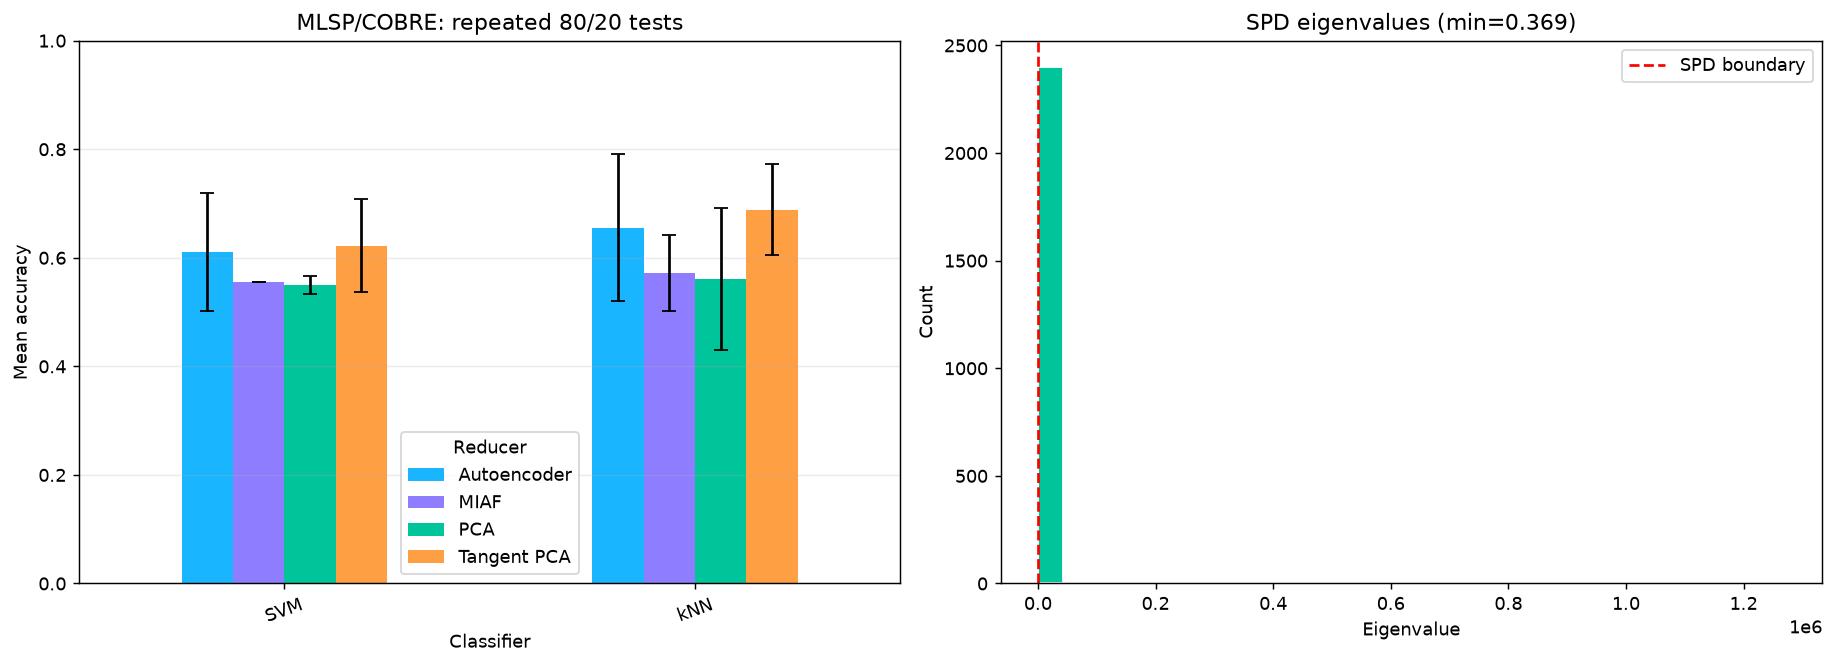

In [ ]:
# Figures: results and SPD verification
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
means = results.pivot(index="Classifier", columns="Reducer", values="Mean accuracy")
errors = results.pivot(index="Classifier", columns="Reducer", values="Std")
means.plot.bar(yerr=errors, capsize=4, ax=axes[0], color=["#19b5fe", "#8e7dff", "#00c49a", "#ff9f43"])
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Mean accuracy")
axes[0].set_title("MLSP/COBRE: repeated 80/20 tests")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(axis="y", alpha=0.25)
axes[0].legend(title="Reducer")

axes[1].hist(spd_eigenvalues.ravel(), bins=30, color="#00c49a", edgecolor="white")
axes[1].axvline(0, color="red", linestyle="--", label="SPD boundary")
axes[1].set_title(f"SPD eigenvalues (min={spd_eigenvalues.min():.3f})")
axes[1].set_xlabel("Eigenvalue")
axes[1].set_ylabel("Count")
axes[1].legend()
plt.show()


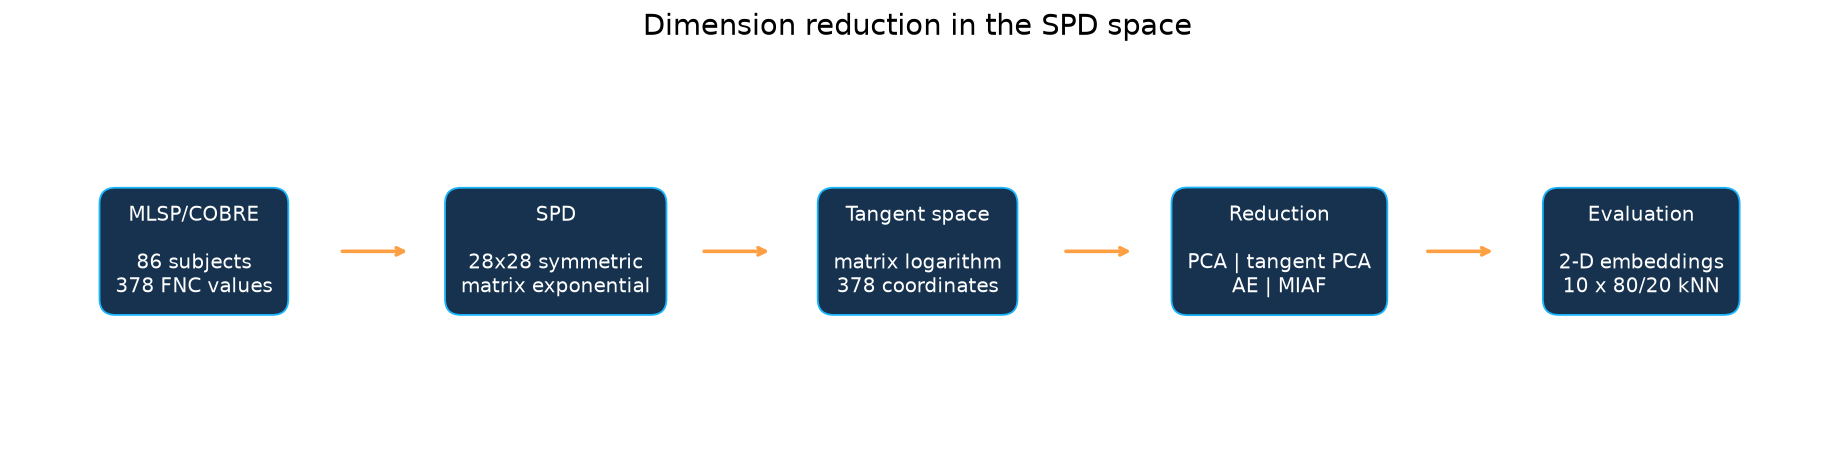

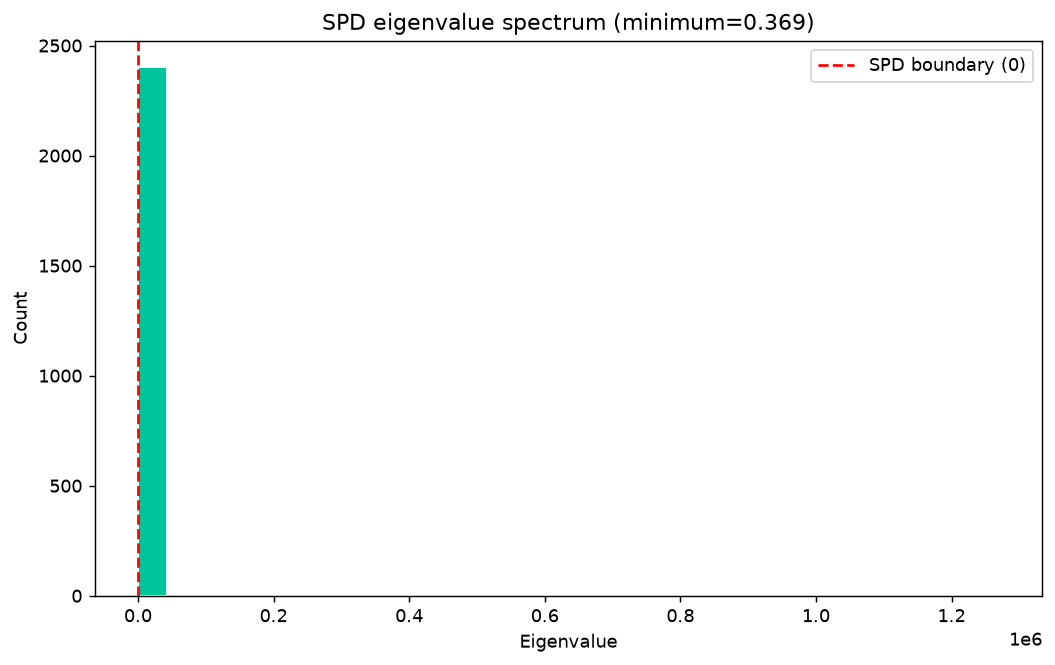

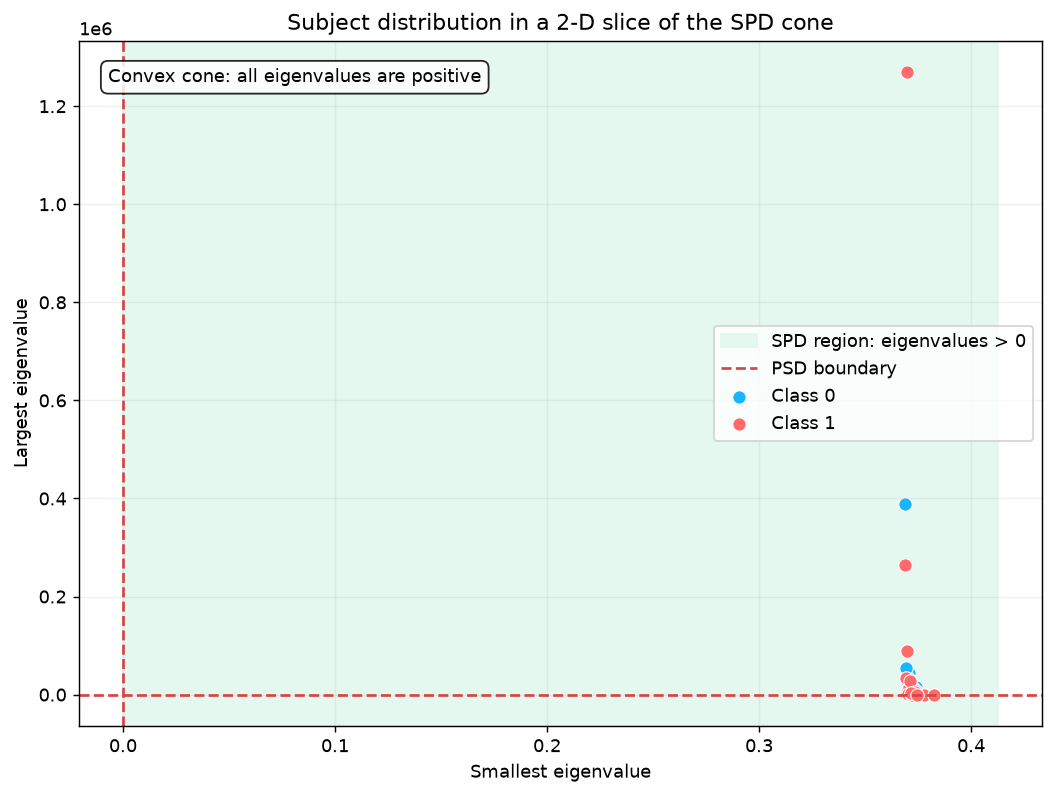

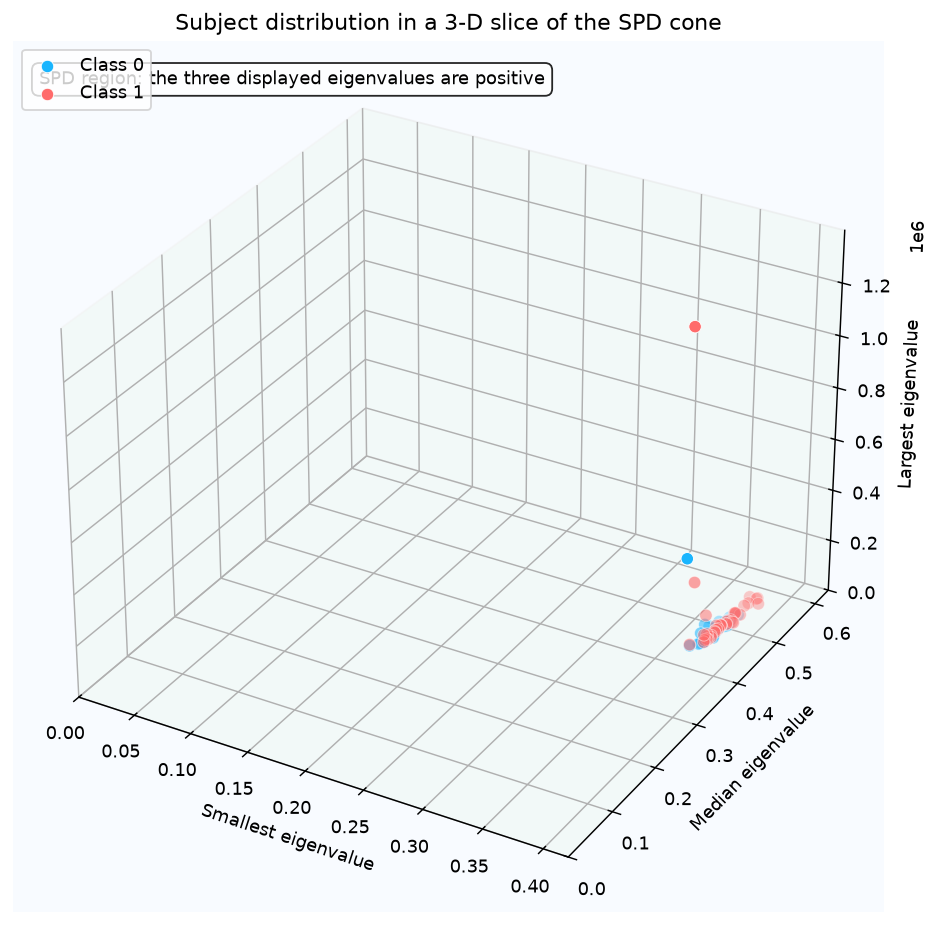

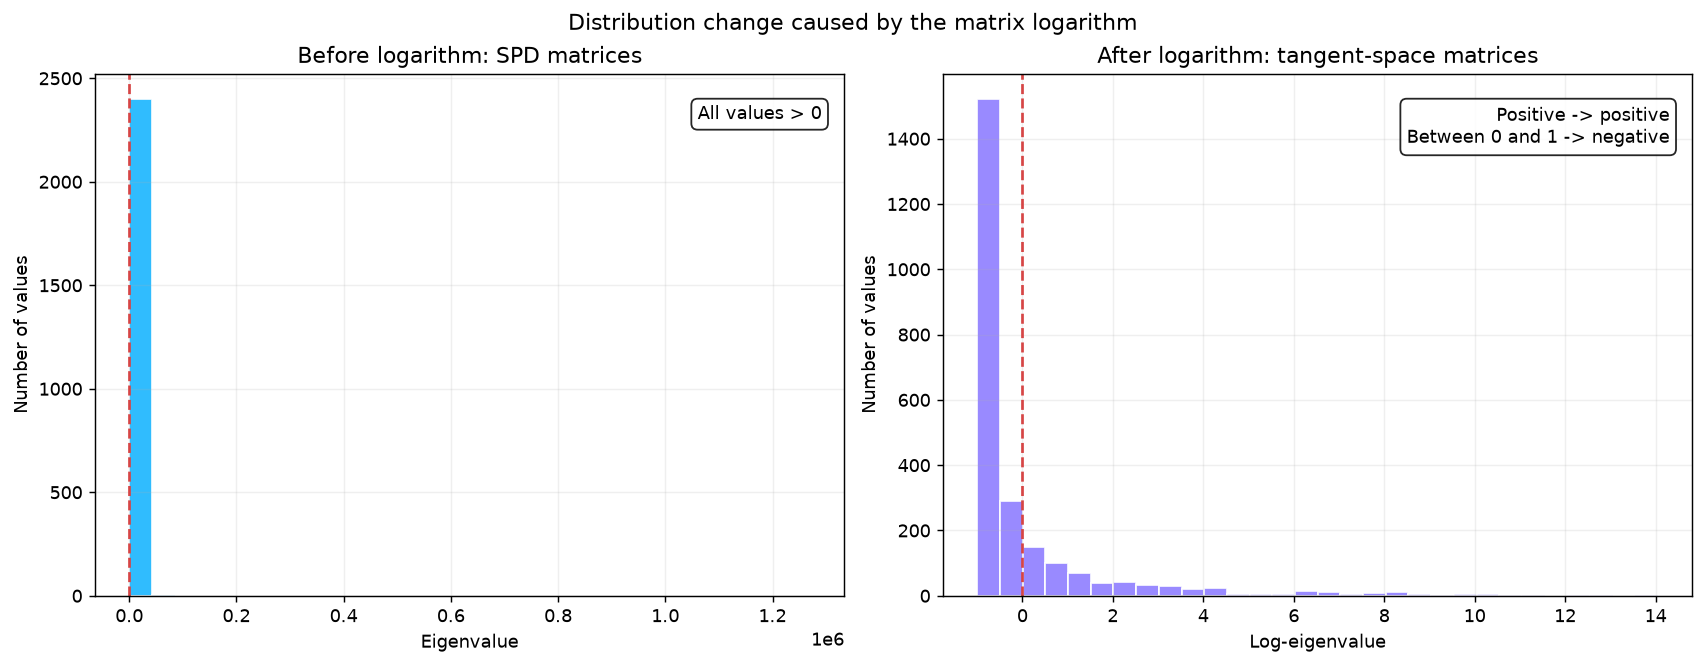

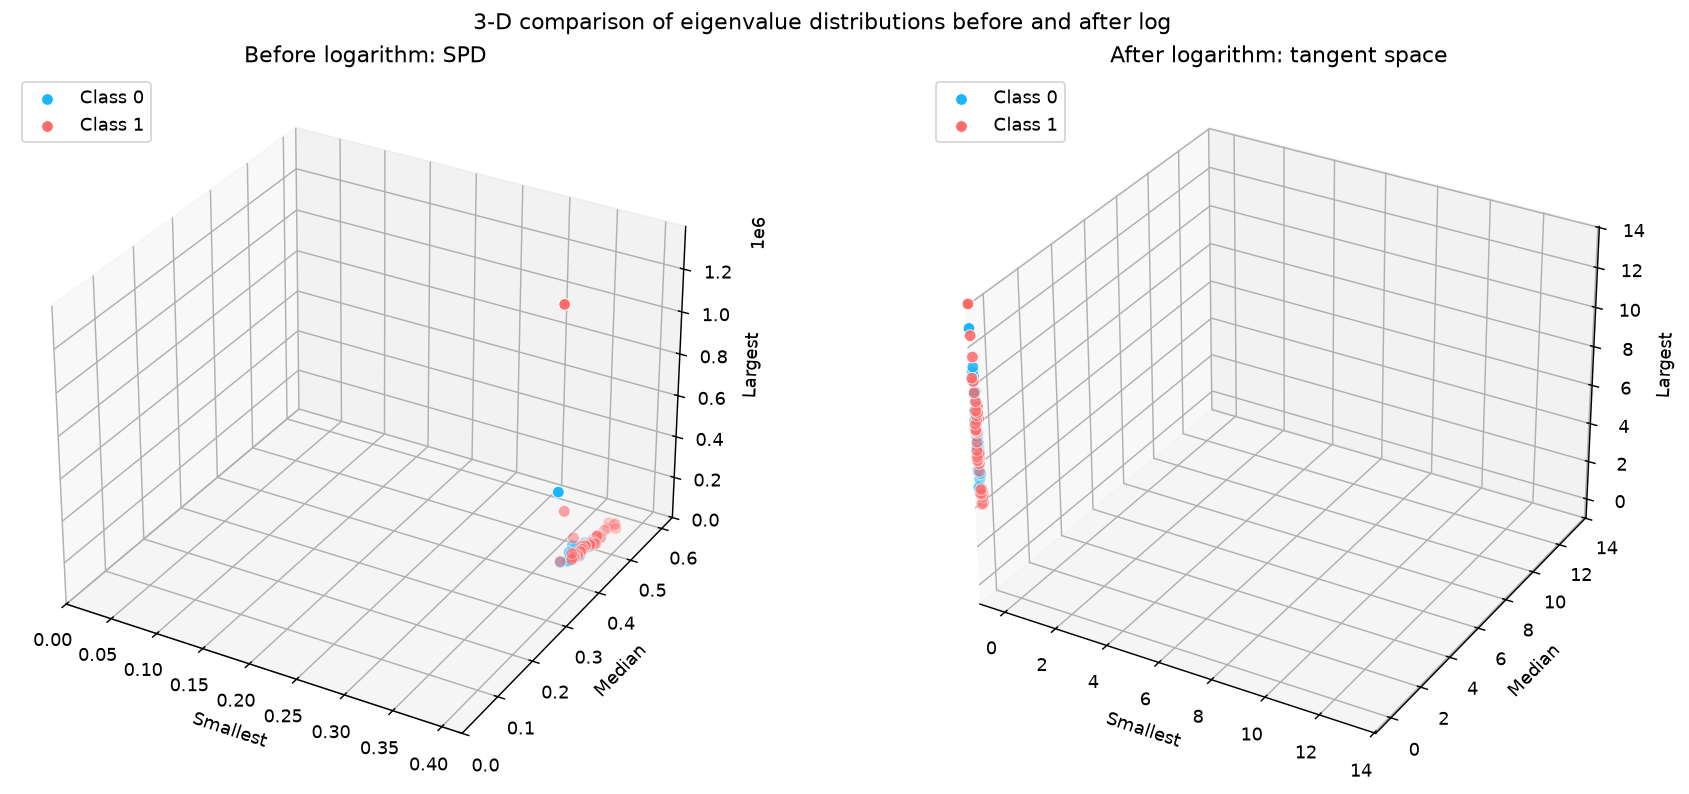

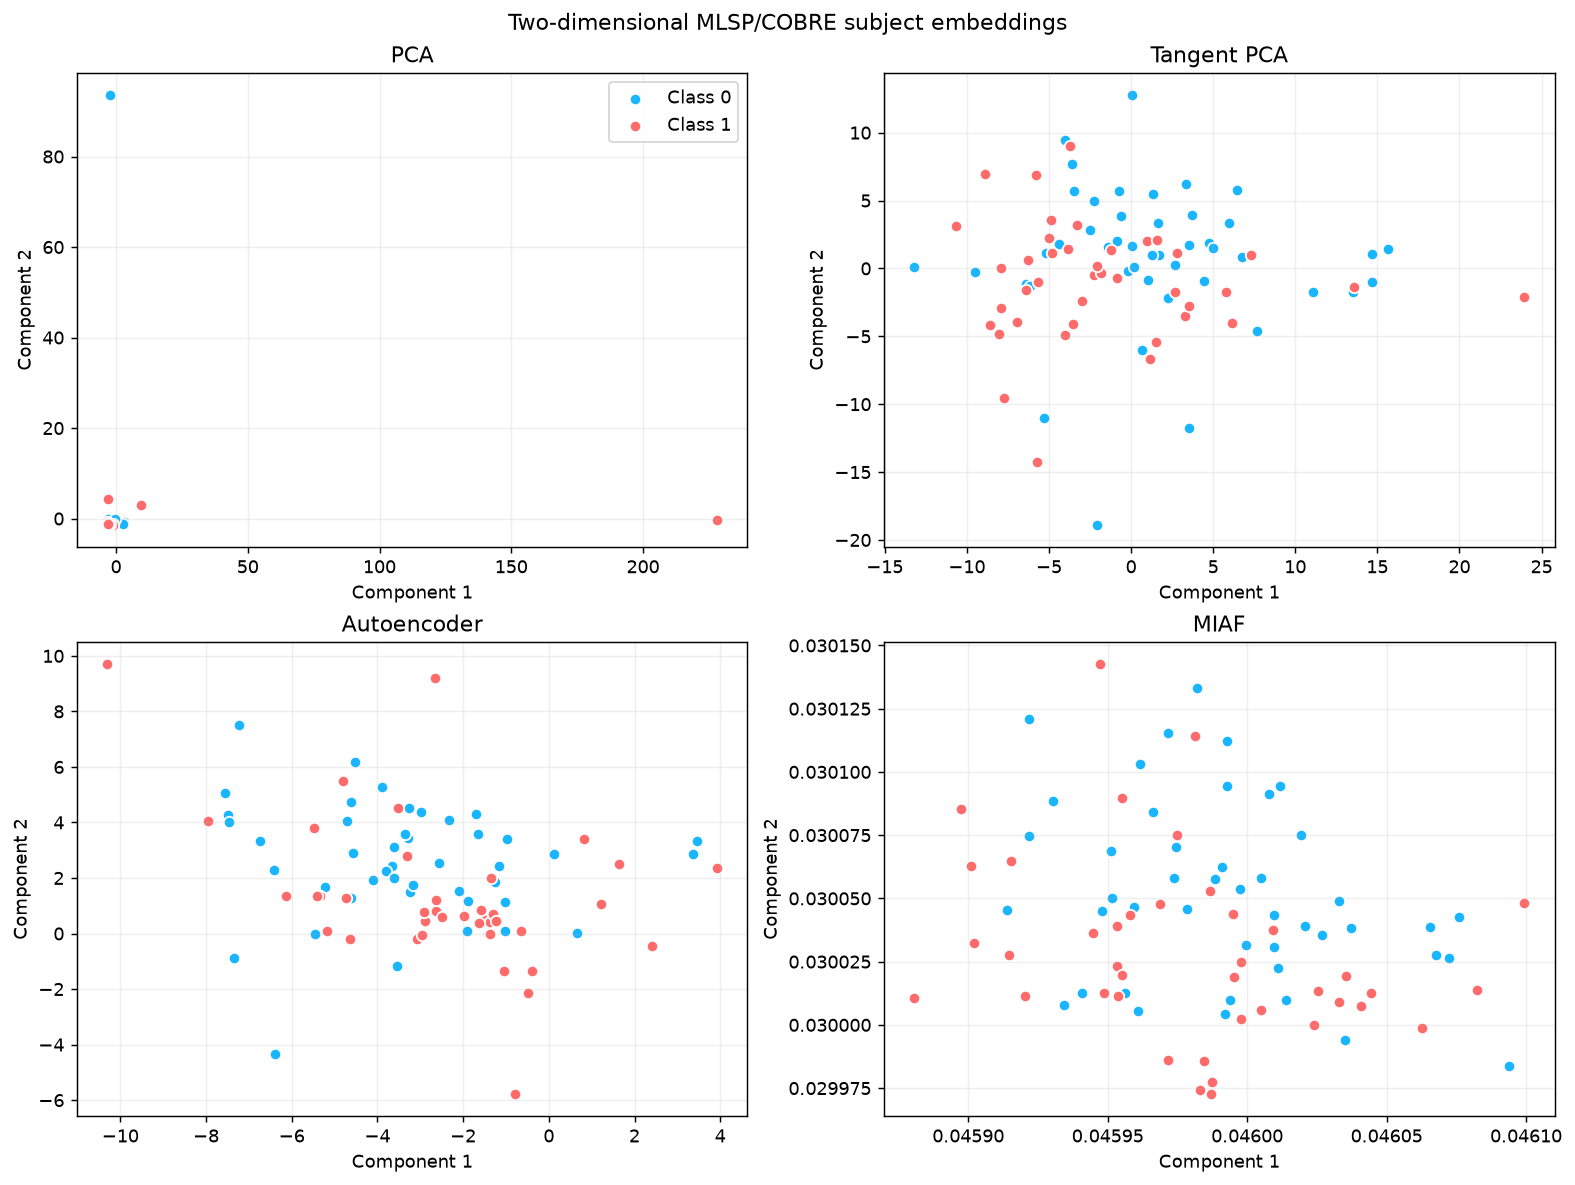

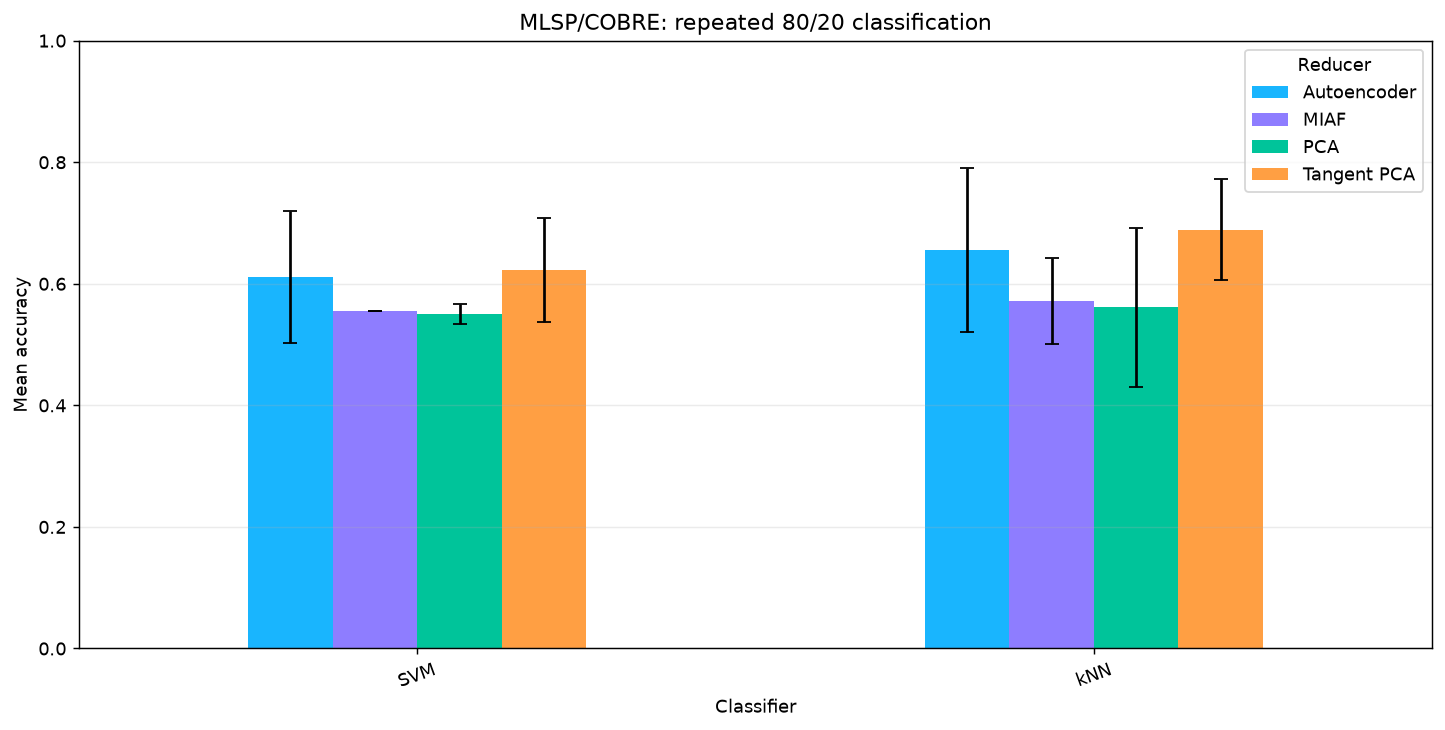

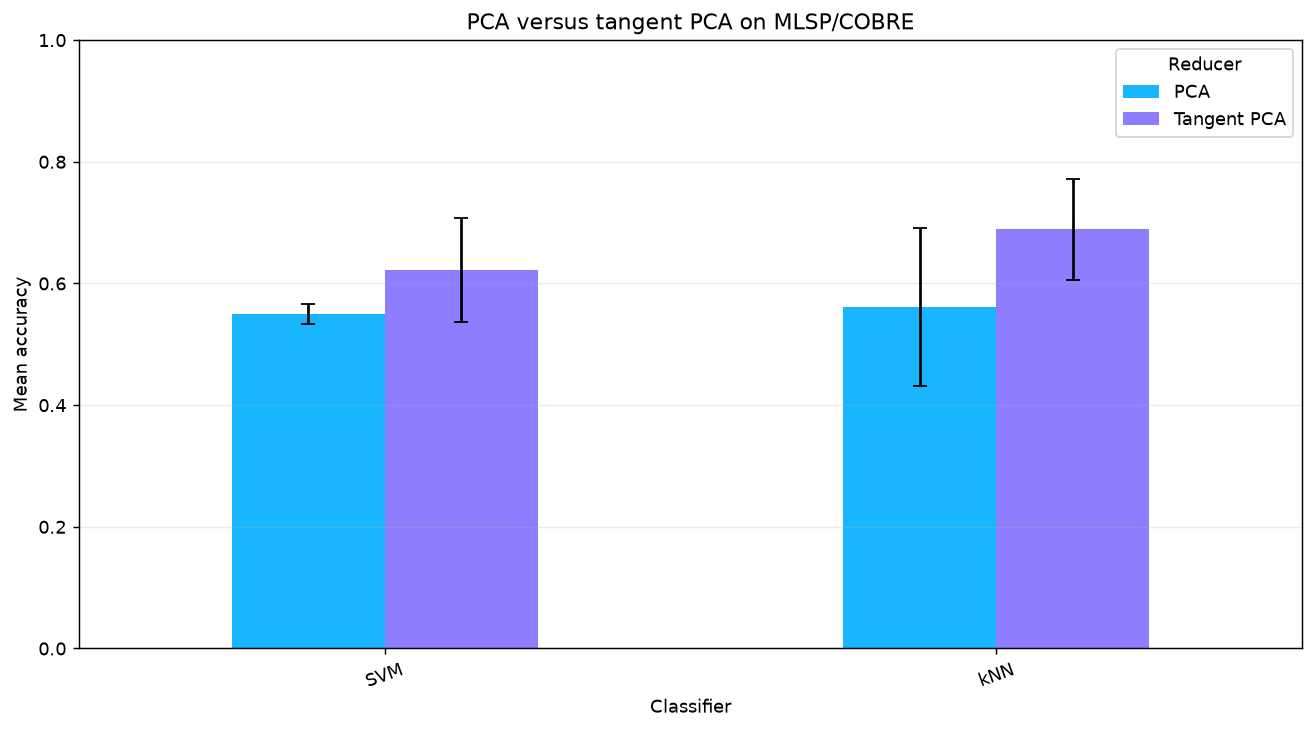

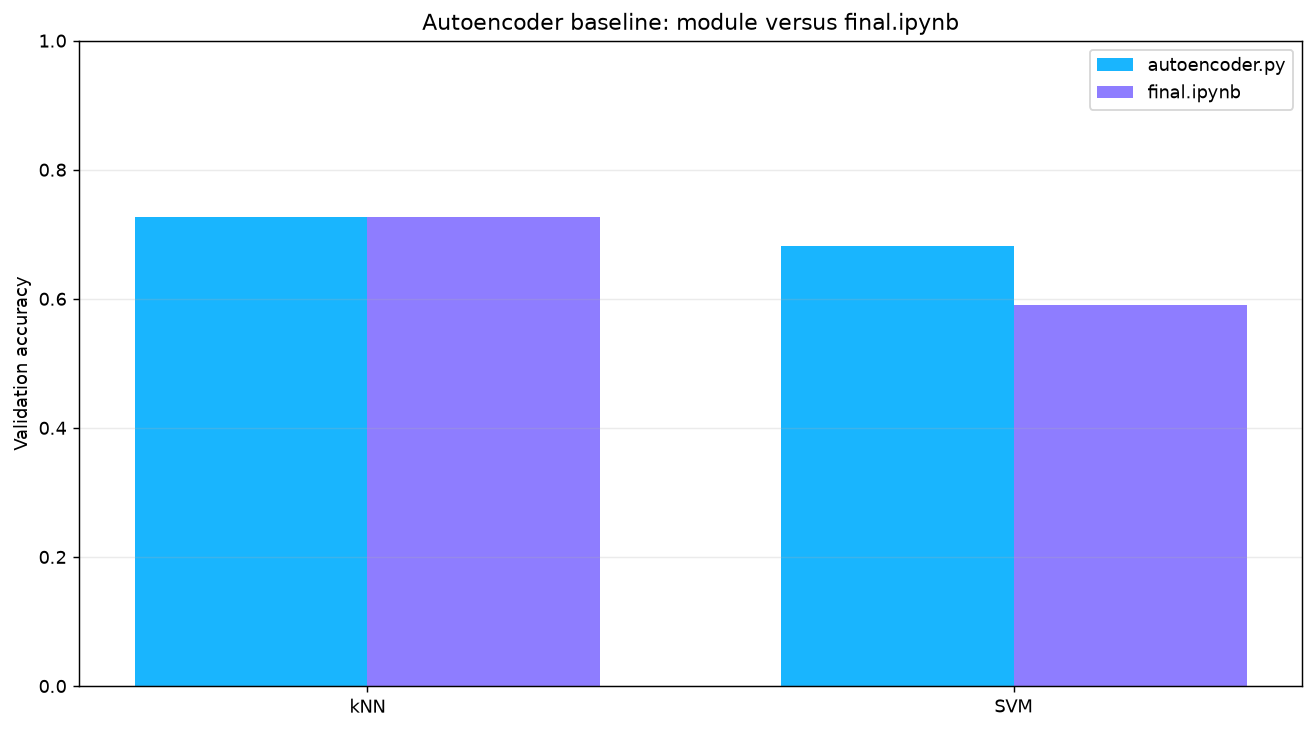

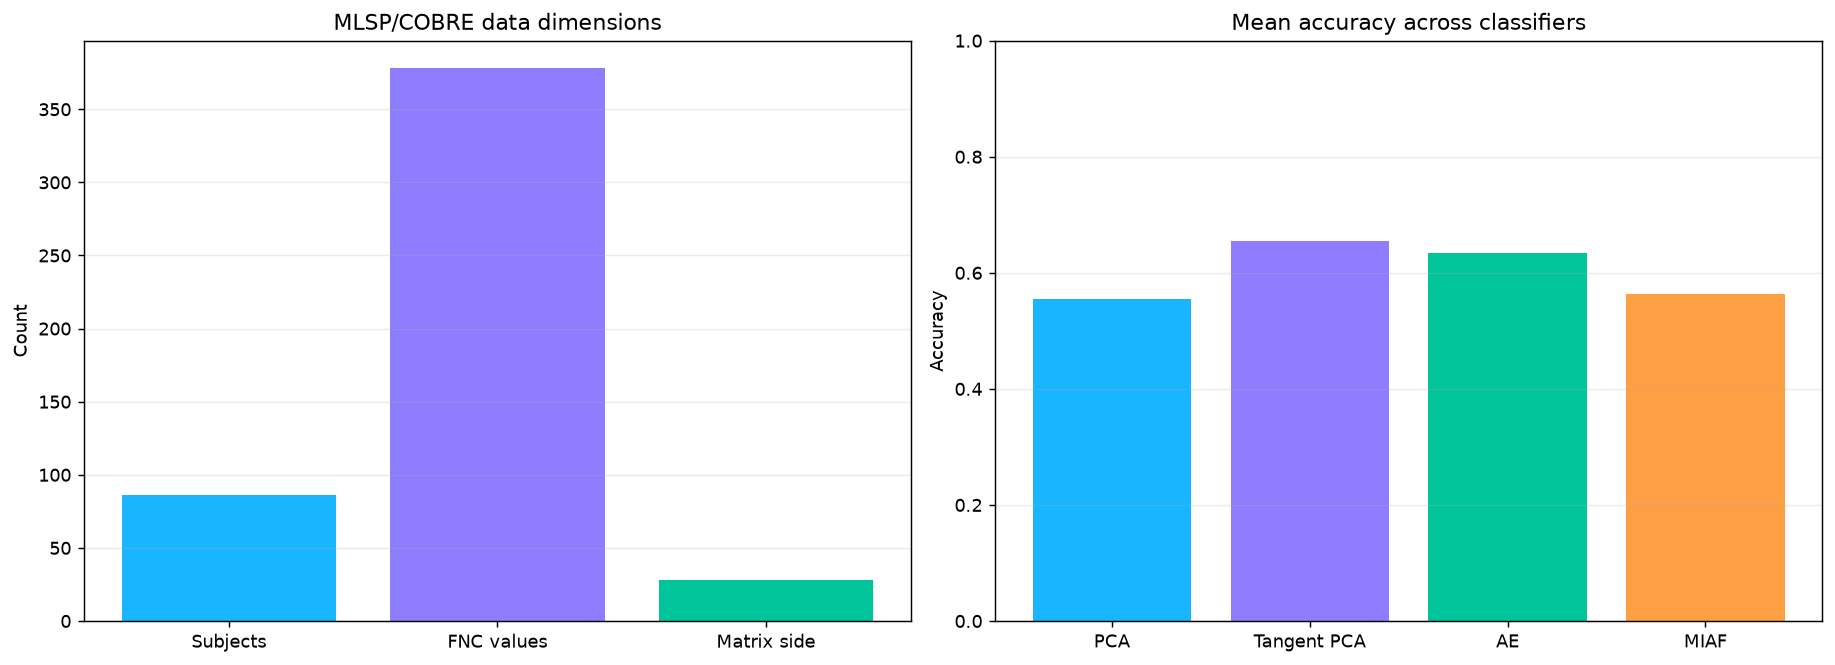

In [ ]:
# Figures generated and integrated directly from notebook variables
from IPython.display import display

embeddings = {
    "PCA": Z_pca,
    "Tangent PCA": Z_tangent_pca,
    "Autoencoder": Z_autoencoder,
    "MIAF": Z_miaf,
}

# 1. Pipeline
fig, axis = plt.subplots(figsize=(14, 3.5), constrained_layout=True)
axis.axis("off")
stages = [
    ("MLSP/COBRE", "86 subjects\n378 FNC values"),
    ("SPD", "28x28 symmetric\nmatrix exponential"),
    ("Tangent space", "matrix logarithm\n378 coordinates"),
    ("Reduction", "PCA | tangent PCA\nAE | MIAF"),
    ("Evaluation", "2-D embeddings\n10 x 80/20 kNN"),
]
positions = np.linspace(0.1, 0.9, len(stages))
for i, (title, detail) in enumerate(stages):
    axis.text(positions[i], 0.5, f"{title}\n\n{detail}", ha="center", va="center",
              color="white", fontsize=11,
              bbox=dict(boxstyle="round,pad=0.8", facecolor="#16324f", edgecolor="#19b5fe"))
    if i < len(stages) - 1:
        axis.annotate("", xy=(positions[i + 1] - 0.08, 0.5),
                      xytext=(positions[i] + 0.08, 0.5),
                      arrowprops=dict(arrowstyle="->", color="#ff9f43", lw=2))
axis.set_title("Dimension reduction in the SPD space", fontsize=16)
display(fig)
fig.savefig(FIGURES / "01_pipeline.png", dpi=180, bbox_inches="tight")
plt.close(fig)

# 2. SPD eigenvalues
fig, axis = plt.subplots(figsize=(8, 5), constrained_layout=True)
axis.hist(spd_eigenvalues.ravel(), bins=30, color="#00c49a", edgecolor="white")
axis.axvline(0, color="red", linestyle="--", label="SPD boundary (0)")
axis.set_title(f"SPD eigenvalue spectrum (minimum={spd_eigenvalues.min():.3f})")
axis.set_xlabel("Eigenvalue")
axis.set_ylabel("Count")
axis.legend()
display(fig)
fig.savefig(FIGURES / "02_spd_eigenvalues.png", dpi=180, bbox_inches="tight")
plt.close(fig)

# 3. Distribution in a 2-D slice of the SPD cone
lambda_min = spd_eigenvalues[:, 0]
lambda_max = spd_eigenvalues[:, -1]
fig, axis = plt.subplots(figsize=(8, 6), constrained_layout=True)
axis.axvspan(0, lambda_min.max() * 1.08, color="#dff7ec", alpha=0.8,
             label="SPD region: eigenvalues > 0")
axis.axvline(0, color="#d64545", linestyle="--", linewidth=1.5,
             label="PSD boundary")
axis.axhline(0, color="#d64545", linestyle="--", linewidth=1.5)
for label, color in [(0, "#19b5fe"), (1, "#ff6b6b")]:
    mask = y == label
    axis.scatter(lambda_min[mask], lambda_max[mask], s=55, color=color,
                 edgecolors="white", linewidths=0.6, label=f"Class {label}")
axis.set_xlabel("Smallest eigenvalue")
axis.set_ylabel("Largest eigenvalue")
axis.set_title("Subject distribution in a 2-D slice of the SPD cone")
axis.text(0.03, 0.96, "Convex cone: all eigenvalues are positive",
          transform=axis.transAxes, va="top", fontsize=10,
          bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.85))
axis.grid(alpha=0.2)
axis.legend()
display(fig)
fig.savefig(FIGURES / "08_spd_cone_distribution.png", dpi=180, bbox_inches="tight")
plt.close(fig)

# 4. Distribution in a 3-D slice of the SPD cone
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

eigenvalue_triplet = np.column_stack([
    spd_eigenvalues[:, 0],
    spd_eigenvalues[:, spd_eigenvalues.shape[1] // 2],
    spd_eigenvalues[:, -1],
])
fig = plt.figure(figsize=(9, 7), constrained_layout=True)
axis = fig.add_subplot(111, projection="3d")
axis.set_facecolor("#f8fbff")
axis.xaxis.pane.set_facecolor("#eef8f2")
axis.yaxis.pane.set_facecolor("#eef8f2")
axis.zaxis.pane.set_facecolor("#eef8f2")
axis.set_xlim(0, eigenvalue_triplet[:, 0].max() * 1.1)
axis.set_ylim(0, eigenvalue_triplet[:, 1].max() * 1.1)
axis.set_zlim(0, eigenvalue_triplet[:, 2].max() * 1.1)
for label, color in [(0, "#19b5fe"), (1, "#ff6b6b")]:
    mask = y == label
    axis.scatter(eigenvalue_triplet[mask, 0],
                 eigenvalue_triplet[mask, 1],
                 eigenvalue_triplet[mask, 2],
                 s=48, color=color, edgecolors="white",
                 linewidths=0.5, label=f"Class {label}")
axis.set_xlabel("Smallest eigenvalue")
axis.set_ylabel("Median eigenvalue")
axis.set_zlabel("Largest eigenvalue")
axis.set_title("Subject distribution in a 3-D slice of the SPD cone")
axis.text2D(
    0.03, 0.95,
    "SPD region: the three displayed eigenvalues are positive",
    transform=axis.transAxes, fontsize=10,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.85),
)
axis.legend(loc="upper left")
display(fig)
fig.savefig(FIGURES / "09_spd_cone_distribution_3d.png", dpi=180, bbox_inches="tight")
plt.close(fig)

# 5. Eigenvalue distribution before and after the matrix logarithm
log_eigenvalues = np.linalg.eigvalsh(log_spd)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
axes[0].hist(spd_eigenvalues.ravel(), bins=30, color="#19b5fe",
             edgecolor="white", alpha=0.9)
axes[0].axvline(0, color="#d64545", linestyle="--", linewidth=1.5)
axes[0].set_title("Before logarithm: SPD matrices")
axes[0].set_xlabel("Eigenvalue")
axes[0].set_ylabel("Number of values")
axes[0].text(
    0.97, 0.94, "All values > 0",
    transform=axes[0].transAxes, ha="right", va="top",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="white", alpha=0.85),
)
axes[0].grid(alpha=0.2)

axes[1].hist(log_eigenvalues.ravel(), bins=30, color="#8e7dff",
             edgecolor="white", alpha=0.9)
axes[1].axvline(0, color="#d64545", linestyle="--", linewidth=1.5)
axes[1].set_title("After logarithm: tangent-space matrices")
axes[1].set_xlabel("Log-eigenvalue")
axes[1].set_ylabel("Number of values")
axes[1].text(
    0.97, 0.94, "Positive -> positive\nBetween 0 and 1 -> negative",
    transform=axes[1].transAxes, ha="right", va="top",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="white", alpha=0.85),
)
axes[1].grid(alpha=0.2)
fig.suptitle("Distribution change caused by the matrix logarithm")
display(fig)
fig.savefig(FIGURES / "10_eigenvalue_distribution_before_after_log.png",
            dpi=180, bbox_inches="tight")
plt.close(fig)

# 6. 3-D comparison before and after the matrix logarithm
fig = plt.figure(figsize=(14, 6), constrained_layout=True)
axis_before = fig.add_subplot(121, projection="3d")
axis_after = fig.add_subplot(122, projection="3d")
triplet_before = np.column_stack([
    spd_eigenvalues[:, 0],
    spd_eigenvalues[:, spd_eigenvalues.shape[1] // 2],
    spd_eigenvalues[:, -1],
])
triplet_after = np.column_stack([
    log_eigenvalues[:, 0],
    log_eigenvalues[:, log_eigenvalues.shape[1] // 2],
    log_eigenvalues[:, -1],
])

for axis, triplet, title in [
    (axis_before, triplet_before, "Before logarithm: SPD"),
    (axis_after, triplet_after, "After logarithm: tangent space"),
]:
    for label, color in [(0, "#19b5fe"), (1, "#ff6b6b")]:
        mask = y == label
        axis.scatter(triplet[mask, 0], triplet[mask, 1], triplet[mask, 2],
                     s=42, color=color, edgecolors="white",
                     linewidths=0.5, label=f"Class {label}")
    axis.set_xlabel("Smallest")
    axis.set_ylabel("Median")
    axis.set_zlabel("Largest")
    axis.set_title(title)
    axis.grid(alpha=0.25)
    axis.legend(loc="upper left")

axis_before.set_xlim(0, triplet_before[:, 0].max() * 1.1)
axis_before.set_ylim(0, triplet_before[:, 1].max() * 1.1)
axis_before.set_zlim(0, triplet_before[:, 2].max() * 1.1)
after_min = triplet_after.min()
after_max = triplet_after.max()
axis_after.set_xlim(after_min, after_max)
axis_after.set_ylim(after_min, after_max)
axis_after.set_zlim(after_min, after_max)
fig.suptitle("3-D comparison of eigenvalue distributions before and after log")
display(fig)
fig.savefig(FIGURES / "11_eigenvalue_distribution_3d_before_after_log.png",
            dpi=180, bbox_inches="tight")
plt.close(fig)

# 7. Four integrated 2-D embeddings
fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
for axis, (name, embedding) in zip(axes.flat, embeddings.items()):
    for label, color in [(0, "#19b5fe"), (1, "#ff6b6b")]:
        mask = y == label
        axis.scatter(embedding[mask, 0], embedding[mask, 1], s=40,
                     color=color, label=f"Class {label}", edgecolors="white")
    axis.set_title(name)
    axis.set_xlabel("Component 1")
    axis.set_ylabel("Component 2")
    axis.grid(alpha=0.2)
axes.flat[0].legend()
fig.suptitle("Two-dimensional MLSP/COBRE subject embeddings")
display(fig)
fig.savefig(FIGURES / "03_subject_embeddings.png", dpi=180, bbox_inches="tight")
plt.close(fig)

# 8. Accuracy comparison for all four reductions
fig, axis = plt.subplots(figsize=(11, 5.5), constrained_layout=True)
accuracy_table = results.pivot(index="Classifier", columns="Reducer", values="Mean accuracy")
error_table = results.pivot(index="Classifier", columns="Reducer", values="Std")
accuracy_table.plot.bar(yerr=error_table, capsize=4, ax=axis,
                        color=["#19b5fe", "#8e7dff", "#00c49a", "#ff9f43"])
axis.set_ylim(0, 1)
axis.set_ylabel("Mean accuracy")
axis.set_title("MLSP/COBRE: repeated 80/20 classification")
axis.tick_params(axis="x", rotation=20)
axis.grid(axis="y", alpha=0.25)
display(fig)
fig.savefig(FIGURES / "04_accuracy_comparison.png", dpi=180, bbox_inches="tight")
plt.close(fig)

# 9. PCA versus tangent PCA
pca_table = results[results["Reducer"].isin(["PCA", "Tangent PCA"])]
fig, axis = plt.subplots(figsize=(10, 5.5), constrained_layout=True)
pca_means = pca_table.pivot(index="Classifier", columns="Reducer", values="Mean accuracy")
pca_errors = pca_table.pivot(index="Classifier", columns="Reducer", values="Std")
pca_means.plot.bar(yerr=pca_errors, capsize=4, ax=axis,
                   color=["#19b5fe", "#8e7dff"])
axis.set_ylim(0, 1)
axis.set_ylabel("Mean accuracy")
axis.set_title("PCA versus tangent PCA on MLSP/COBRE")
axis.tick_params(axis="x", rotation=20)
axis.grid(axis="y", alpha=0.25)
display(fig)
fig.savefig(FIGURES / "07_mlsp_pca_vs_tangent_pca.png", dpi=180, bbox_inches="tight")
plt.close(fig)

# 10. Autoencoder implementation comparison on the common 64/22 split
classifier_names = ["kNN", "SVM"]
module_scores = [0.7273, 0.6818]
notebook_scores = [0.7273, 0.5909]
x = np.arange(len(classifier_names))
fig, axis = plt.subplots(figsize=(10, 5.5), constrained_layout=True)
axis.bar(x - 0.18, module_scores, width=0.36, label="autoencoder.py", color="#19b5fe")
axis.bar(x + 0.18, notebook_scores, width=0.36, label="final.ipynb", color="#8e7dff")
axis.set_xticks(x, classifier_names)
axis.set_ylim(0, 1)
axis.set_ylabel("Validation accuracy")
axis.set_title("Autoencoder baseline: module versus final.ipynb")
axis.legend()
axis.grid(axis="y", alpha=0.25)
display(fig)
fig.savefig(FIGURES / "06_autoencoder_comparison.png", dpi=180, bbox_inches="tight")
plt.close(fig)

# 11. Compact full summary
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
axes[0].bar(["Subjects", "FNC values", "Matrix side"], [86, 378, 28],
            color=["#19b5fe", "#8e7dff", "#00c49a"])
axes[0].set_title("MLSP/COBRE data dimensions")
axes[0].set_ylabel("Count")
axes[0].grid(axis="y", alpha=0.25)
axes[1].bar(["PCA", "Tangent PCA", "AE", "MIAF"],
            [results[results.Reducer == name]["Mean accuracy"].mean()
             for name in ["PCA", "Tangent PCA", "Autoencoder", "MIAF"]],
            color=["#19b5fe", "#8e7dff", "#00c49a", "#ff9f43"])
axes[1].set_ylim(0, 1)
axes[1].set_title("Mean accuracy across classifiers")
axes[1].set_ylabel("Accuracy")
axes[1].grid(axis="y", alpha=0.25)
display(fig)
fig.savefig(FIGURES / "05_full_results_summary.png", dpi=180, bbox_inches="tight")
plt.close(fig)


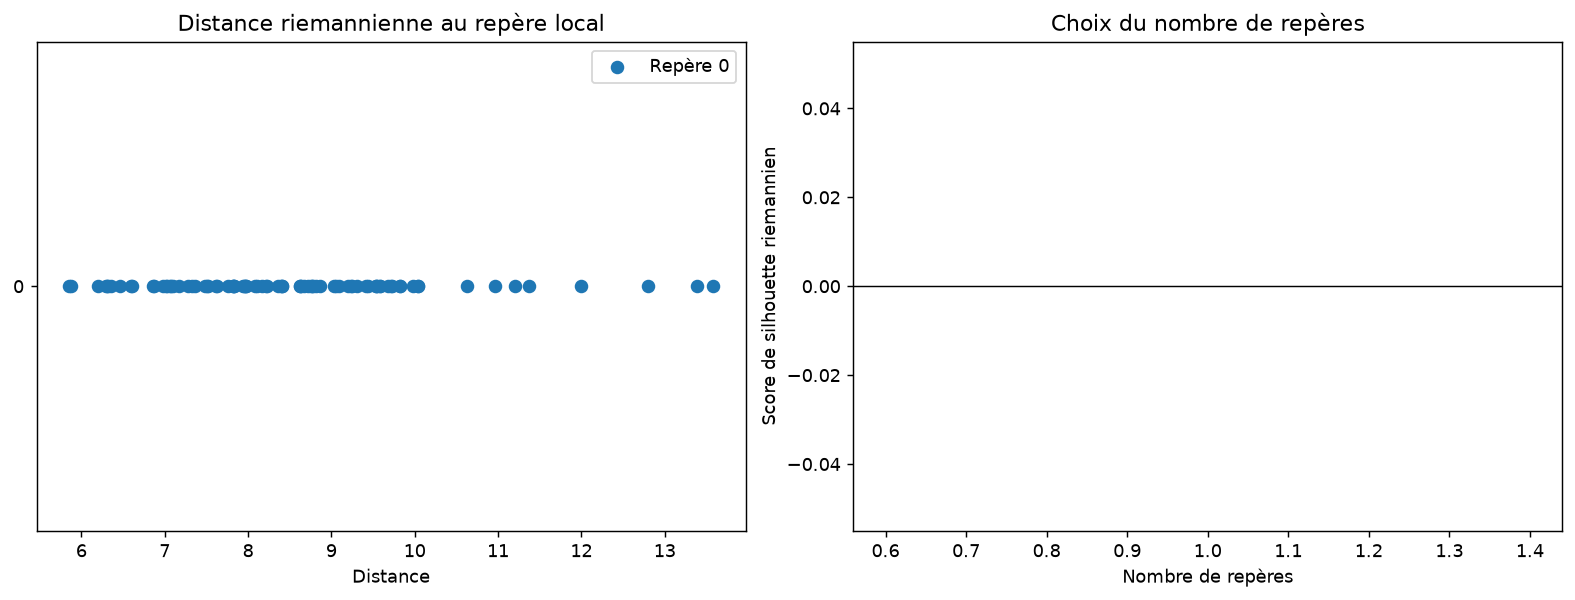

In [ ]:
# Local geometry figures
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for reference in range(local_summary["n_centers"]):
    mask = local_assignments == reference
    axes[0].scatter(
        local_distance[mask],
        np.zeros(mask.sum()) + reference,
        s=42,
        label=f"Repère {reference}",
    )
axes[0].set_title("Distance riemannienne au repère local")
axes[0].set_xlabel("Distance")
axes[0].set_yticks(range(local_summary["n_centers"]))
axes[0].legend()

axes[1].bar(
    list(local_summary["silhouette_scores"]),
    list(local_summary["silhouette_scores"].values()),
    color="#8e7dff",
)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Choix du nombre de repères")
axes[1].set_xlabel("Nombre de repères")
axes[1].set_ylabel("Score de silhouette riemannien")
display(fig)
fig.savefig(FIGURES / "08_local_geometry_multi_reference.png", dpi=180, bbox_inches="tight")
plt.close(fig)


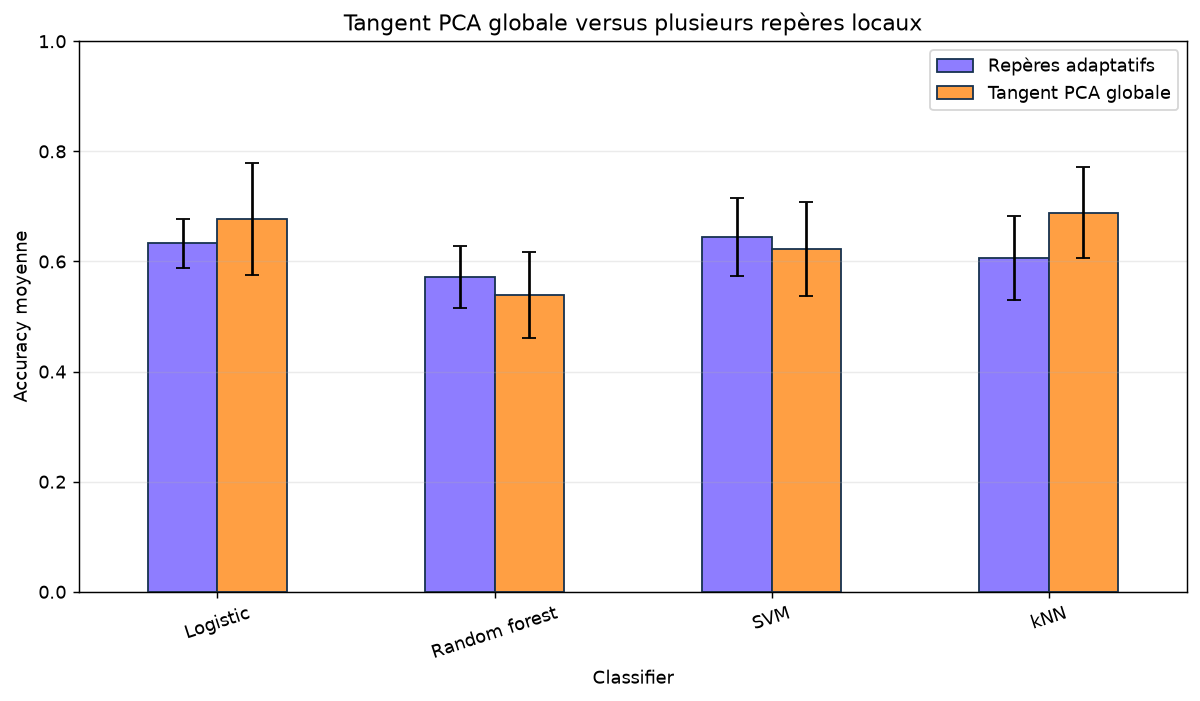

In [ ]:
# Accuracy figure for the local-geometry comparison
plot_data = local_accuracy.pivot(
    index="Classifier", columns="Reducer", values="Mean_Accuracy"
)
plot_errors = local_accuracy.pivot(
    index="Classifier", columns="Reducer", values="Std_Accuracy"
)
axis = plot_data.plot.bar(
    figsize=(11, 5.5), yerr=plot_errors, capsize=4,
    color=["#8e7dff", "#ff9f43"], edgecolor="#16324f",
)
axis.set_ylim(0, 1)
axis.set_ylabel("Accuracy moyenne")
axis.set_title("Tangent PCA globale versus plusieurs repères locaux")
axis.grid(axis="y", alpha=0.25)
axis.tick_params(axis="x", rotation=18)
axis.legend(title="")
display(axis.get_figure())
axis.get_figure().savefig(
    FIGURES / "09_local_geometry_accuracy.png", dpi=180, bbox_inches="tight"
)
plt.close(axis.get_figure())


### Key result

The best result in the MLSP/COBRE comparison is obtained by tangent PCA.
The eigenvalue plot confirms that all 86 generated \(28\times28\) matrices
are SPD. The cone plot shows that every subject lies in the positive
eigenvalue region. The 3-D cone view uses the smallest, median, and largest
eigenvalues as a readable slice of the full space. The SPD set is convex,
while its usual geometric
structure is non-Euclidean, which motivates the tangent-space mapping. The
before/after eigenvalue plot shows how the matrix logarithm changes the scale
of the SPD eigenvalues.

In [ ]:
# Save all measured results
results.to_csv(ROOT / "integrated_mlsp_results.csv", index=False)
print("saved:", ROOT / "integrated_mlsp_results.csv")


saved: C:\Users\Globaltech\Reduction-des-matrices-SPD\integrated_mlsp_results.csv


## Code extrait : rep?res multiples adaptatifs

Cette cellule utilise le module r?utilisable `spd_reduction.multi_reference`. Le nombre de rep?res est s?lectionn? ? partir des donn?es d'entra?nement, puis les coordonn?es tangentielles locales sont align?es dans un espace commun.

In [ ]:
from spd_reduction.multi_reference import (
    fit_multi_reference_tangent,
    transform_multi_reference_tangent,
)

# Ajuster uniquement sur les matrices d'entra?nement.
local_train, local_centers, local_assignments, local_summary = (
    fit_multi_reference_tangent(spd_train)
)
print("Nombre de rep?res:", local_summary["n_centers"])
print("Taille des coordonn?es:", local_train.shape)

# Pour de nouvelles matrices, r?utiliser les rep?res appris.
local_test, test_assignments = transform_multi_reference_tangent(
    spd_test, local_centers, global_center
)


## Dataset 2 ? ETH-80 as Gaussian SPD descriptors

ETH-80 is evaluated separately from MLSP/COBRE. It contains 80 objects from 8 categories, 41 views per object, and each object becomes a 401x401 Gaussian SPD descriptor. The strict benchmark uses 5 training and 5 test objects per category. The companion notebook workflow uses k=6, d=30, 1-NN, and transductive Lie-LLE fitted on train plus test.

In [ ]:
# ETH-80 results already generated by the reproducible scripts
eth80_notebook = pd.read_csv(ROOT / "eth80_notebook_benchmark.csv")
eth80_strict = pd.read_csv(ROOT / "eth80_spd_results.csv")
display(eth80_notebook)
display(eth80_strict)


### ETH-80 reproduction commands

The raw ETH-80 image directory is intentionally separate from this notebook. After downloading it into `ETH-80/`, run:

```powershell
python -m scripts.run_eth80_notebook_benchmark
python -m scripts.test_eth80_spd
```

The first command reproduces the friend's notebook workflow; the second is the strict train-only GPU benchmark.

## Dataset 3 ? Synthetic SPD overlap and spherical log-SPD data

The paper-style data uses S=exp((A+A^T)/2), which guarantees SPD matrices. The final overlap comparison keeps only moderate and strong overlap and uses 2000 matrices per case with 50/50 train/test splits. The spherical experiment normalizes each symmetric logarithm to Frobenius norm one before applying the exponential, then generates two class directions with moderate or strong overlap.

In [ ]:
# Paper synthetic results without the distant case
paper_results = pd.read_csv(ROOT / "paper_spd_reductions_comparison_no_distant.csv")
display(paper_results)

# Spherical benchmark results
sphere_results = pd.read_csv(ROOT / "synthetic_notebook_lie_lle_benchmark.csv")
sphere_results = sphere_results[sphere_results["Case"].astype(str).str.contains("Sphere|Sph")].copy()
display(sphere_results)


### Combined interpretation

- MLSP/COBRE uses real brain connectomes reconstructed as 28x28 SPD matrices.
- ETH-80 uses image-set Gaussian covariance descriptors of size 401x401.
- Paper overlap data uses 5x5 synthetic SPD matrices.
- Spherical data constrains the logarithmic SPD descriptors to a unit Frobenius sphere.
- Accuracy is not the same as neighbour preservation: PCA may preserve global variance while adaptive references preserve local charts, and Lie-LLE targets local reconstruction structure.

In [ ]:
# Compact comparison tables for the three data families
eth80_display = eth80_notebook.copy()
if "Accuracy" in eth80_display.columns:
    eth80_display = eth80_display.rename(columns={
        "Accuracy": "Accuracy (%)",
        "Accuracy_std": "Accuracy std (%)",
        "Neighbor preservation": "Neighbours preserved (%)",
    })
summary_tables = {
    "ETH-80 notebook": eth80_display,
    "Paper overlap": paper_results[["Case", "Method", "Mean accuracy", "Neighbor preservation"]],
    "Spherical": sphere_results[["Case", "Method", "Mean accuracy", "Neighbor preservation"]],
}
for name, table in summary_tables.items():
    print("\n" + name)
    display(table)
